
# CS3920/CS5920 Lab Worksheet 5 — Linear models in scikit-learn

Author: Ayaan Malik  
Date: 3 November 2025

This notebook follows the worksheet structure: Least Squares, Ridge, and Lasso. It reproduces the key cells and includes short answers to Exercises 1–5.


In [1]:

# In[1]: imports and config
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# scikit-learn
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.datasets import load_diabetes

# mglearn (installed manually from https://github.com/amueller/mglearn)
try:
    import mglearn
    HAVE_MGLEARN = True
except Exception as e:
    HAVE_MGLEARN = False
    print("mglearn not found. Place the 'mglearn' folder in your home directory or site-packages.")
    print("Proceeding with a minimal fallback where possible.")


## 2. Least squares

w[0]: 0.393906  b: -0.031804


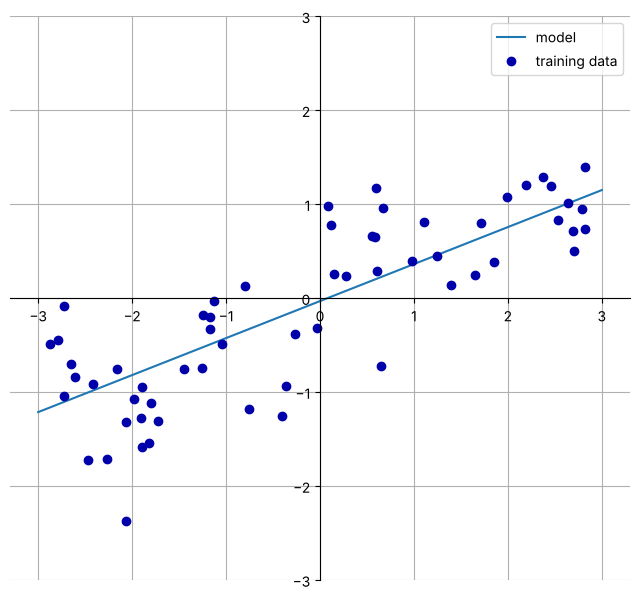

In [2]:

# In[2]: lecture figure (requires mglearn)
if HAVE_MGLEARN:
    mglearn.plots.plot_linear_regression_wave()
else:
    print("Skipped: mglearn lecture figure.")


In [3]:

# In[3]: Wave dataset and LinearRegression
if HAVE_MGLEARN:
    X, y = mglearn.datasets.make_wave(n_samples=60)
else:
    # Fallback: synthetic wave-like data
    rs = np.random.RandomState(42)
    X = rs.uniform(-3, 3, size=(60, 1))
    y = np.sin(X[:,0]) + rs.normal(scale=0.25, size=60)
    X = X.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
lr = LinearRegression().fit(X_train, y_train)


In [4]:

# In[4] and In[5]: coefficients
print("lr.coef_:", lr.coef_)
print("lr.intercept_:", lr.intercept_)


lr.coef_: [0.39390555]
lr.intercept_: -0.031804343026759746


In [5]:

# In[6] and In[7]: R^2 scores
print("Train R^2:", lr.score(X_train, y_train))
print("Test  R^2:", lr.score(X_test, y_test))


Train R^2: 0.6700890315075756
Test  R^2: 0.65933685968637


In [6]:

# In[8]: extend features with X^2
X_train_ext = np.concatenate((X_train, X_train**2), axis=1)
X_test_ext  = np.concatenate((X_test,  X_test**2),  axis=1)


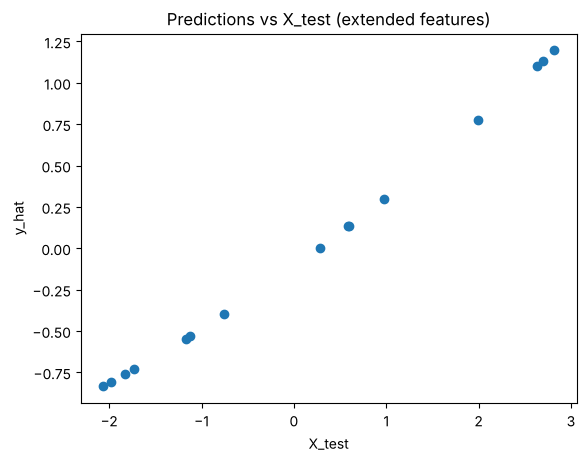

In [7]:

# In[9]: fit on extended features and scatter
lr_ext = LinearRegression().fit(X_train_ext, y_train)
y_hat = lr_ext.predict(X_test_ext)

plt.figure()
plt.scatter(X_test, y_hat)
plt.title("Predictions vs X_test (extended features)")
plt.xlabel("X_test")
plt.ylabel("y_hat")
plt.show()


In [8]:

# In[10]: R^2 with extended features
print(lr_ext.score(X_train_ext, y_train))
print(lr_ext.score(X_test_ext, y_test))


0.6753386938063954
0.6377346604142682


## Expanded diabetes dataset with interactions

In [9]:

# In[11] and In[12]: load and expand
diabetes = load_diabetes()
print(diabetes.data.shape)

poly = PolynomialFeatures(degree=2, include_bias=False)
X = poly.fit_transform(diabetes.data)
y = diabetes.target
print(X.shape)


(442, 10)
(442, 65)


In [10]:

# In[13]: split and fit LinearRegression
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
lr = LinearRegression().fit(X_train, y_train)


In [11]:

# In[14]: overfitting check
print(lr.score(X_train, y_train))
print(lr.score(X_test, y_test))


0.6048153298370549
0.424241945945943


## 3. Ridge regression

In [12]:

# In[15] and In[16]: Ridge with default alpha=1.0
ridge = Ridge().fit(X_train, y_train)
print(ridge.score(X_train, y_train))
print(ridge.score(X_test, y_test))


0.42791319284620444
0.4387018239867466


In [13]:

# In[17] and In[18]: Ridge with alpha=10
ridge10 = Ridge(alpha=10).fit(X_train, y_train)
print(ridge10.score(X_train, y_train))
print(ridge10.score(X_test, y_test))


0.15099790967423454
0.15644986167540842


In [14]:

# Ridge with alpha=0.1 (ridge01)
ridge01 = Ridge(alpha=0.1).fit(X_train, y_train)
print(ridge01.score(X_train, y_train))
print(ridge01.score(X_test, y_test))


0.5149371236445714
0.49537663053177594


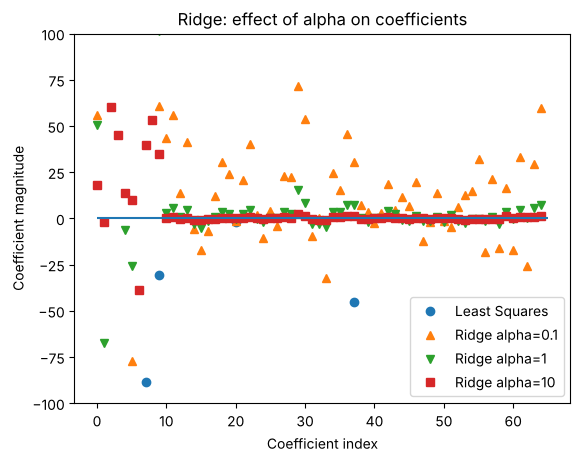

In [15]:

# In[19]: coefficient paths (Least Squares vs Ridge)
plt.figure()
plt.plot(lr.coef_, 'o', label="Least Squares")
plt.plot(ridge01.coef_, '^', label="Ridge alpha=0.1")
plt.plot(ridge.coef_,  'v', label="Ridge alpha=1")
plt.plot(ridge10.coef_, 's', label="Ridge alpha=10")
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.hlines(0, 0, len(lr.coef_))
plt.ylim(-100, 100)
plt.legend()
plt.title("Ridge: effect of alpha on coefficients")
plt.show()


## 4. Lasso

In [16]:

# In[20] and In[21]: Lasso default alpha=1.0
lasso = Lasso().fit(X_train, y_train)
print(lasso.score(X_train, y_train))
print(lasso.score(X_test, y_test))


0.34687336241710987
0.3791413953419156


In [17]:

# In[22]: sparsity
import numpy as np
print(np.sum(lasso.coef_ != 0))


3


In [18]:

# In[23], In[24], In[25]: Lasso alpha=0.01 with more iterations
lasso001 = Lasso(alpha=0.01, max_iter=100000).fit(X_train, y_train)
print(lasso001.score(X_train, y_train))
print(lasso001.score(X_test, y_test))
print(np.sum(lasso001.coef_ != 0))


0.5375042588015271
0.5144146595591166
16


In [19]:

# In[26], In[27], In[28]: Lasso alpha=0.0001
lasso00001 = Lasso(alpha=0.0001, max_iter=100000).fit(X_train, y_train)
print(lasso00001.score(X_train, y_train))
print(lasso00001.score(X_test, y_test))
print(np.sum(lasso00001.coef_ != 0))


0.6011668318910374
0.4479479256263247
55


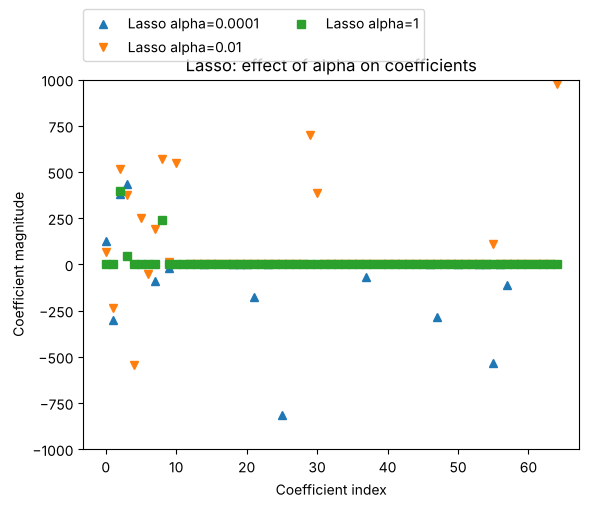

In [20]:

# In[29]: Lasso coefficient plot for different alphas
plt.figure()
plt.plot(lasso00001.coef_, '^', label="Lasso alpha=0.0001")
plt.plot(lasso001.coef_,   'v', label="Lasso alpha=0.01")
plt.plot(lasso.coef_,      's', label="Lasso alpha=1")
plt.legend(ncol=2, loc=(0, 1.05))
plt.ylim(-1000, 1000)
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.title("Lasso: effect of alpha on coefficients")
plt.show()



## 5. Exercises — short answers

**1. Coefficient sizes vs α in Ridge (Fig. In[19]).**  
As α increases, coefficients shrink toward 0 uniformly. `alpha=0.1` sits close to least squares. `alpha=1` shrinks more. `alpha=10` shrinks strongly. This is expected from L2-penalisation.

**2. Role of `plt.hlines(0,0,len(lr.coef_))`.**  
Draws a horizontal reference line at 0 across the x-range of indices to make it easy to see sign and shrinkage.

**3. Coefficient sizes vs α in Lasso (Fig. In[29]).**  
As α decreases, more coefficients become nonzero and magnitudes jump in piecewise-linear fashion. Unlike Ridge, many coefficients are set exactly to 0 for larger α, producing sparsity. The plot shows abrupt entries/exits at 0. Ridge plot shows smooth shrinkage without zeros.

**4. Meaning of `np.sum(lasso.coef_ != 0)`.**  
Counts how many features have nonzero weight under Lasso, i.e., the number of selected features after L1 regularisation.

**5. Role of `plt.legend(ncol=2, loc=(0,1.05))`.**  
Places the legend above the axes and uses two columns to avoid overlapping the data.
